# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Вербицький Юрій Віталійович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 3      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 3: Харків, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

встановлюю: osmnx, h3 ...
усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_харків


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g

COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')

    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)

        COST[name] = {
            'спосіб': 'знімок',
            'записів': len(g),
            'передано_МБ': 0.0,
            'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
            'секунд': round(time.time() - t0, 3)
        }
        return g

    b0 = cache_bytes()
    t0 = time.time()

    g = clean(getter())
    g.to_parquet(path, index=False)

    elapsed = time.time() - t0
    transferred_mb = max(0, cache_bytes() - b0) / 1e6
    file_mb = os.path.getsize(path) / 1e6

    COST[name] = {
        'спосіб': 'живий запит',
        'записів': len(g),
        'передано_МБ': round(transferred_mb, 3),
        'файл_МБ': round(file_mb, 3),
        'секунд': round(elapsed, 3)
    }

    return g

    # ----- ВАШ КОД: живий запит -----
    # 1) запам'ятайте cache_bytes() і час ДО виклику getter()
    # 2) викличте getter(), проженіть результат через clean(), збережіть у path
    # 3) запишіть у COST[name] спосіб 'живий запит', записів, передано_МБ,
    #    файл_МБ і секунд
    raise NotImplementedError('напишіть гілку живого запиту')

In [10]:
import time
import requests
import osmnx as ox

def retry_getter(getter, attempts=5):
    for attempt in range(attempts):
        try:
            return getter()
        except Exception as e:
            message = str(e).lower()

            retryable = any(x in message for x in [
                '502', '503', '504',
                '429', 'timeout',
                'timed out', 'connection'
            ])

            if not retryable or attempt == attempts - 1:
                raise

            wait = 5 * (2 ** attempt)
            print(f'Помилка запиту. Повтор через {wait} с...')
            time.sleep(wait)

In [11]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 353.5 км²


In [12]:
heritage = fetch('heritage', lambda: retry_getter(
    lambda: ox.features_from_polygon(
        poly, {'historic': True, 'tourism': TOURISM_OK}
    )
))

stations = fetch('stations', lambda: retry_getter(
    lambda: ox.features_from_polygon(
        poly, {'railway': ['station', 'halt'],
               'building': ['train_station']}
    )
))

amenities = fetch('amenities', lambda: retry_getter(
    lambda: ox.features_from_polygon(
        poly, {'amenity': ['cafe', 'restaurant',
                           'drinking_water', 'toilets']}
    )
))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = retry_getter(
    lambda: ox.graph_from_polygon(poly, network_type='walk')
    )
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

Помилка запиту. Повтор через 5 с...
вузлів 65453 | ребер 188794


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [13]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.046,0.05
heritage,знімок,807,0.0,0.199,0.104
stations,знімок,88,0.0,0.071,0.062
amenities,живий запит,1383,0.553,0.176,78.747
мережа walk,живий запит,254247,27.085,12.511,211.5


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [14]:
# ----- ВАШ КОД -----

# Об'єднання двох умов: historic або tourism
mask = heritage['historic'].notna() | heritage['tourism'].notna()

# Залишаємо об'єкти, які мають відповідні теги та назву
cand = heritage[mask & heritage['name'].notna()].copy()

# Прибираємо старий індекс OSM
cand = cand.reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('відкинуто без name     :', int(mask.sum()) - len(cand))
print('відкинуто за тегами    :', len(heritage) - int(mask.sum()))

# print('підходять за тегами    :', ...)
# print('з них мають name       :', ...)

усього у шарі heritage : 807
підходять за тегами    : 807
з них мають name       : 712
відкинуто без name     : 95
відкинуто за тегами    : 0


In [15]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial       267
aircraft        33
monument        24
locomotive      15
railway_car     10
yes             10
tank             9
cannon           7
vehicle          5
building         4

=== tourism ===
tourism
artwork       186
attraction     92
museum         36
gallery        14
viewpoint      13

типи геометрії: {'Point': 626, 'Polygon': 86}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [16]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)


# Наявність посилання на Wikidata або Wikipedia
cand['wiki'] = (
    cand['wikidata'].notna() | cand['wikipedia'].notna()
).astype(int)

# Кількість заповнених назв різними мовами
name_cols = [col for col in cand.columns if col.startswith('name:')]
cand['n_lang'] = cand[name_cols].notna().sum(axis=1)

# Нормалізація сигналів до шкали від 0 до 1
wiki_rank = cand['wiki'].rank(pct=True)
lang_rank = cand['n_lang'].rank(pct=True)
tourism_rank = cand['tourism'].isin(
    ['museum', 'gallery', 'attraction', 'artwork', 'viewpoint']
).astype(int).rank(pct=True)
historic_rank = cand['historic'].notna().astype(int).rank(pct=True)
area_rank = np.log1p(cand['area_m2']).rank(pct=True)

# Підсумковий рейтинг
cand['score'] = (
    0.30 * wiki_rank +
    0.25 * lang_rank +
    0.20 * tourism_rank +
    0.20 * historic_rank +
    0.05 * area_rank
)

cand = cand.sort_values('score', ascending=False)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають tourism:', int(cand['tourism'].notna().sum()))
print('мають historic:', int(cand['historic'].notna().sum()))

display(
    cand[['name', 'historic', 'tourism', 'wiki', 'n_lang',
          'area_m2', 'score']].head(15)
)


кандидатів   : 712
мають wiki   : 93
мають tourism: 341
мають historic: 393


,name,historic,tourism,wiki,n_lang,area_m2,score
637,Кенаса у Харкові,synagogue,attraction,1,4,296.528483,0.869487
69,Танк Т-34-85,tank,attraction,1,3,0.000000,0.806461
22,Пам'ятник студбатівцям,memorial,artwork,1,3,0.000000,0.806461
74,Половецькі баби,yes,attraction,1,3,0.000000,0.806461
73,100-мм польова гармата БС-3,cannon,attraction,1,3,0.000000,0.806461
72,76-мм дивізійна гармата зразка 1942 року (ЗІС-3),cannon,attraction,1,3,0.000000,0.806461
71,122-мм гаубиця зразка 1938 року (М-30),cannon,attraction,1,3,0.000000,0.806461
76,Половецькі баби,yes,attraction,1,3,0.000000,0.806461
75,Половецькі баби,yes,attraction,1,3,0.000000,0.806461
77,Половецькі баби,yes,attraction,1,3,0.000000,0.806461


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [17]:
N_SMALL, N_LARGE = 10, 30

# ----- ВАШ КОД -----

N_SMALL, N_LARGE = 10, 30

# Перші 30 об'єктів за власним рейтингом
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10 = top_score.head(N_SMALL)

# Перші 10 об'єктів за площею
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)

# Кількість спільних об'єктів у двох списках
score_names = set(top10['name'])
area_names = set(top_naive['name'])
overlap = len(score_names & area_names)

print('Перетин за назвами: %d з %d' % (overlap, N_SMALL))

display(pd.DataFrame({
    'за вашим критерієм': list(top10['name']),
    'за площею': list(top_naive['name'])
}))


Перетин за назвами: 0 з 10


,за вашим критерієм,за площею
0,Кенаса у Харкові,"Меморіальний комплекс жертв Голокосту ""Дробиць..."
1,Танк Т-34-85,Донецьке городище
2,Пам'ятник студбатівцям,Музей історії і техніки Південної залізниці
3,Половецькі баби,Будинок зі шпилем
4,100-мм польова гармата БС-3,Американська гірка
5,76-мм дивізійна гармата зразка 1942 року (ЗІС-3),Будівлі колишнього заводу барона Едварда Ферди...
6,122-мм гаубиця зразка 1938 року (М-30),Братська та індивідуальні могили радянських во...
7,Половецькі баби,Автошкола
8,Половецькі баби,Будівлі колишнього заводу барона Едварда Ферди...
9,Половецькі баби,Старий цирк


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [18]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----

pairs = close_pairs(top_score, limit_m=60)

if not pairs:
    print('Пар ближче 60 м не знайдено.')
else:
    for i, j, distance in pairs:
        name1 = top_score.iloc[i]['name']
        name2 = top_score.iloc[j]['name']

        print(f'{distance:.1f} м | {name1} — {name2}')


1.5 м | Половецькі баби — Половецькі баби
1.5 м | Половецькі баби — Половецькі баби
1.9 м | Половецькі баби — Половецькі баби
2.9 м | Половецькі баби — Половецькі баби
3.2 м | Половецькі баби — Половецькі баби
4.3 м | 76-мм дивізійна гармата зразка 1942 року (ЗІС-3) — 122-мм гаубиця зразка 1938 року (М-30)
4.4 м | 100-мм польова гармата БС-3 — 76-мм дивізійна гармата зразка 1942 року (ЗІС-3)
4.4 м | Половецькі баби — Половецькі баби
8.7 м | 100-мм польова гармата БС-3 — 122-мм гаубиця зразка 1938 року (М-30)
16.8 м | Танк Т-34-85 — 100-мм польова гармата БС-3
17.9 м | Танк Т-34-85 — Mark V
19.3 м | Дзеркальний струмінь — Дзеркальний струмінь
21.1 м | Танк Т-34-85 — 76-мм дивізійна гармата зразка 1942 року (ЗІС-3)
25.3 м | Танк Т-34-85 — 122-мм гаубиця зразка 1938 року (М-30)
34.4 м | 100-мм польова гармата БС-3 — Mark V
38.5 м | 76-мм дивізійна гармата зразка 1942 року (ЗІС-3) — Mark V
38.9 м | Танк Т-34-85 — Харківський історичний музей
40.1 м | 100-мм польова гармата БС-3 — Харківськ

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [19]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 88
                     name  railway building
0             Новоселівка     halt     <NA>
1        Історичний музей  station     <NA>
2             Університет  station     <NA>
3               Вокзальна  station     <NA>
4      Майдан Конституції  station     <NA>
5                  Левада  station     <NA>
6               Спортивна  station     <NA>
7               Заводська  station     <NA>
8               Турбоатом  station     <NA>
9            Палац Спорту  station     <NA>
10              Армійська  station     <NA>
11  Ім. О.С. Масельського  station     <NA>


In [20]:
# ----- ВАШ КОД -----
station = stations[
    stations['name'].fillna('').str.contains(
        'Харків-Пасажирський|Харків', case=False, regex=True
    )
    & stations['railway'].eq('station')
]

print(station[['name', 'railway', 'building']].to_string())

assert len(station) > 0, 'Станцію не знайдено — перевірте назви у stations'

station = station.iloc[[0]].copy()
print('старт:', station['name'].iloc[0])

                   name  railway building
30   Харків-Слобідський  station     <NA>
36  Харків-Сортувальний  station     <NA>
37  Харків-Пасажирський  station     <NA>
40     Харків-Вантажний  station     <NA>
65         Харків-Ліски  station     <NA>
68        Харків-Левада  station     <NA>
старт: Харків-Слобідський


In [21]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 65453 вузлів, 187018 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [22]:
def check_snap(points, ids, dist, label):
    n_points = len(points)
    n_nodes = len(np.unique(ids))

    print(f'=== {label} ===')
    print('кількість точок        :', n_points)
    print('кількість різних вузлів:', n_nodes)

    if len(dist) > 0:
        print('медіана відстані, м    :', round(float(np.median(dist)), 2))
        print('максимум відстані, м   :', round(float(np.max(dist)), 2))
    else:
        print('медіана відстані, м    : немає даних')
        print('максимум відстані, м   : немає даних')

    if n_nodes < n_points:
        print('\nУВАГА: кілька точок прив’язалися до однакових вузлів.')

        groups = {}
        for i, node_id in enumerate(ids):
            groups.setdefault(node_id, []).append(i)

        for node_id, indices in groups.items():
            if len(indices) > 1:
                names = [str(points.iloc[i]['name']) for i in indices]
                print(f'Вузол {node_id}: {", ".join(names)}')
    else:
        print('\nПеревірку пройдено: кожна точка має окремий вузол.')


---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [25]:

def straight_matrix(points):
    """Матриця прямих віддалей між точками в метрах."""
    points_m = points.to_crs(32635)
    xy = np.column_stack((
        points_m.geometry.x,
        points_m.geometry.y
    ))

    diff = xy[:, None, :] - xy[None, :, :]
    D = np.sqrt((diff ** 2).sum(axis=2))

    np.fill_diagonal(D, 0.0)
    return D


def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)

    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(
            G, s, weight='length'
        )
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)

    np.fill_diagonal(D, 0.0)
    return D


def detour_factor(D, E):
    """Медіана відношення дорожньої віддалі до прямої."""
    mask = (
        np.isfinite(D) &
        np.isfinite(E) &
        (E > 0)
    )
    np.fill_diagonal(mask, False)
    ratios = D[mask] / E[mask]

    if len(ratios) == 0:
        return np.nan

    return float(np.median(ratios))


**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [26]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

=== мала задача ===
кількість точок        : 11
кількість різних вузлів: 8
медіана відстані, м    : 13.2
максимум відстані, м   : 19.74

УВАГА: кілька точок прив’язалися до однакових вузлів.
Вузол 6758702829: Половецькі баби, Половецькі баби, Половецькі баби
Вузол 8242338567: 100-мм польова гармата БС-3, 76-мм дивізійна гармата зразка 1942 року (ЗІС-3)
матриця за 5.370 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.26


Для пішохідної мережі отримано асиметрію 0 м. Це означає, що відстані між усіма парами точок однакові в обох напрямках. Такий результат свідчить про симетричність найкоротших шляхів у побудованому графі. На відміну від автомобільної мережі, де односторонній рух може спричиняти відмінності, у використаному пішохідному графі таких відмінностей не виявлено.

> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [27]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    n = len(D)
    unvisited = set(range(1, n))
    tour = [0]
    current = 0

    while unvisited:
        next_node = min(unvisited, key=lambda node: D[current, node])
        tour.append(next_node)
        unvisited.remove(next_node)
        current = next_node

    tour.append(0)
    return tour


def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = tour.copy()
    n = len(best)
    improved = True

    while improved:
        improved = False

        for i in range(1, n - 2):
            for j in range(i + 1, n - 1):
                candidate = best[:i] + best[i:j + 1][::-1] + best[j + 1:]

                if tour_length(D, candidate) < tour_length(D, best):
                    best = candidate
                    improved = True

    return best

In [28]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [29]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [30]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,13467,0.0
2-opt,13467,0.0
Held-Karp (точний),13467,0.0



оптимальний порядок:
   0. СТАРТ: Харків-Слобідський
   1. Пам'ятник студбатівцям
   2. Половецькі баби
   3. 122-мм гаубиця зразка 1938 року (М-30)
   4. 76-мм дивізійна гармата зразка 1942 року (ЗІС-3)
   5. 100-мм польова гармата БС-3
   6. Танк Т-34-85
   7. Половецькі баби
   8. Половецькі баби
   9. Половецькі баби
  10. Кенаса у Харкові
  11. СТАРТ: Харків-Слобідський

довжина: 13.47 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [31]:
# ----- ВАШ КОД: таблиця зростання -----

ns = [11, 16, 21, 26, 31]

rows = []

for n in ns:
    cells = 2**(n - 1) * (n - 1)
    memory_gb = cells * 8 / 10**9

    rows.append({
        'n': n,
        'клітин': cells,
        'пам’ять, ГБ': memory_gb
    })

growth = pd.DataFrame(rows)

print(growth.to_string(
    index=False,
    formatters={'пам’ять, ГБ': '{:.4f}'.format}
))

 n      клітин пам’ять, ГБ
11       10240      0.0001
16      491520      0.0039
21    20971520      0.1678
26   838860800      6.7109
31 32212254720    257.6980


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

Точний розв'язок задачі комівояжера для 30 точок є практично недоступним через експоненційне зростання обсягу пам'яті алгоритму Held–Karp. Для \(n=31\), враховуючи стартову точку, потрібно зберігати приблизно 32,2 млрд клітин у двох таблицях, що за оцінкою 8 байтів на клітину становить близько 257,7 ГБ пам'яті. Це перевищує обсяг оперативної пам'яті більшості персональних комп'ютерів, а реальна реалізація на Python потребуватиме ще більше пам'яті через накладні витрати структур даних. Тому алгоритм може завершитися помилкою нестачі пам'яті ще до отримання результату. Для такої кількості точок доцільно застосовувати евристичні методи, наприклад найближчого сусіда та 2-opt.

In [32]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

=== велика задача ===
кількість точок        : 31
кількість різних вузлів: 28
медіана відстані, м    : 13.2
максимум відстані, м   : 451.38

УВАГА: кілька точок прив’язалися до однакових вузлів.
Вузол 6758702829: Половецькі баби, Половецькі баби, Половецькі баби
Вузол 8242338567: 100-мм польова гармата БС-3, 76-мм дивізійна гармата зразка 1942 року (ЗІС-3)
коефіцієнт обходу: 1.18
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    57586 м
2-opt            :    54015 м  за 0.031 с  (коротше на 6.2%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

Середнє ребро комірки: 201 м
Усього кандидатів: 712
Зайнятих H3-комірок: 238
Максимум кандидатів в одній комірці: 36


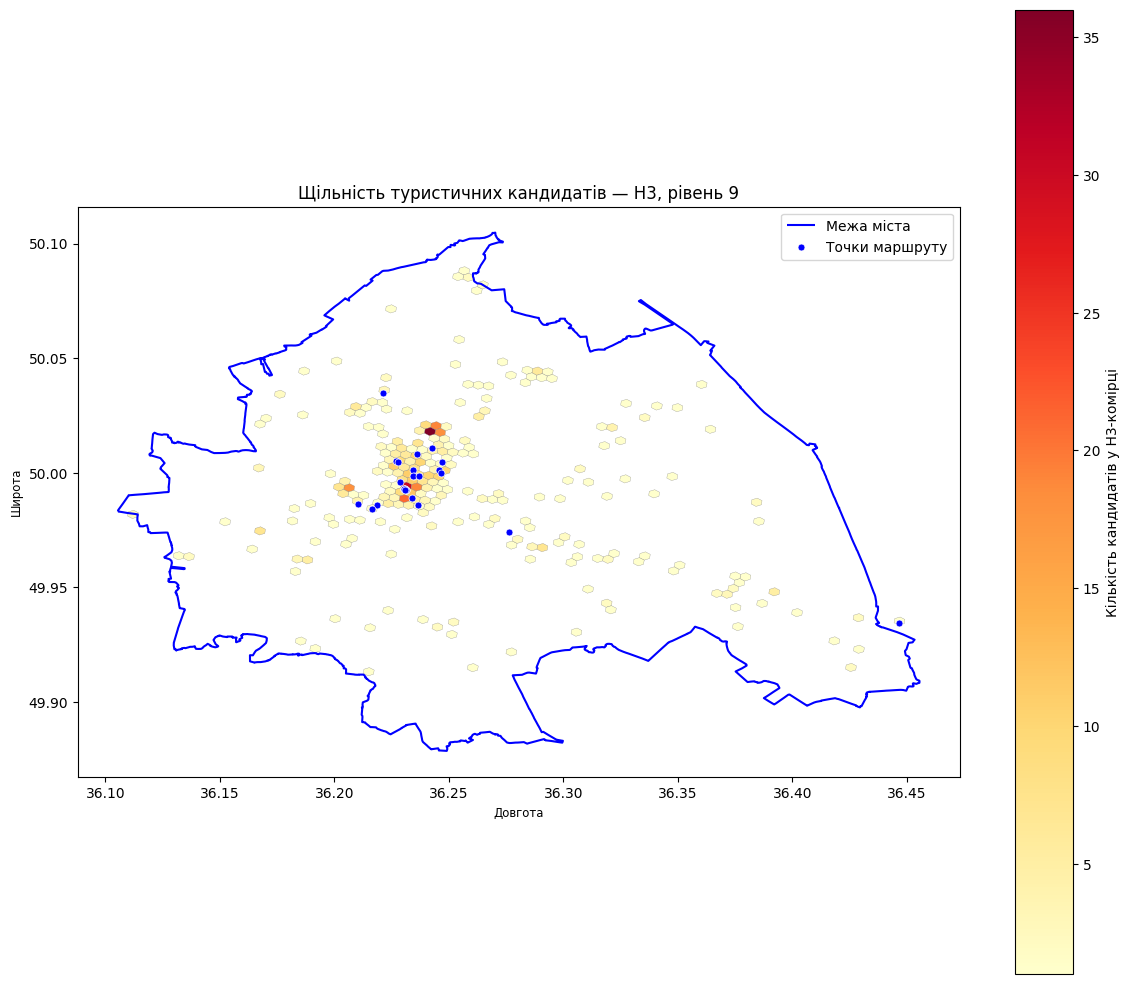

In [35]:

import h3
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

from shapely.geometry import Polygon

H3_RES = 9

print(
    'Середнє ребро комірки: %.0f м'
    % h3.average_hexagon_edge_length(H3_RES, unit='m')
)

# 1. Усі кандидати
cand_map = cand[cand.geometry.notna()].copy().to_crs('EPSG:4326')

representative = cand_map.geometry.apply(
    lambda g: g if g.geom_type == 'Point' else g.representative_point()
)

# 2. Прив'язуємо кожного кандидата до H3-комірки
cand_map['h3'] = representative.apply(
    lambda p: h3.latlng_to_cell(p.y, p.x, H3_RES)
)

# 3. Кількість кандидатів у кожній комірці
dens = cand_map.groupby('h3').size().rename('count').reset_index()

print('Усього кандидатів:', len(cand_map))
print('Зайнятих H3-комірок:', len(dens))
print('Максимум кандидатів в одній комірці:', dens['count'].max())

# 4. Геометрія шестикутників
hexes = gpd.GeoDataFrame(
    dens,
    geometry=[
        Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])
        for cell in dens['h3']
    ],
    crs='EPSG:4326'
)

# 5. Межа міста
city_boundary = gpd.GeoDataFrame(
    geometry=[poly],
    crs='EPSG:4326'
)

# 6. Точки великого маршруту
# Використовуємо наявні точки, якщо вони вже створені
try:
    route_map = pts30.to_crs('EPSG:4326')
except NameError:
    route_map = make_points(top_score).to_crs('EPSG:4326')

# 7. Карта щільності
fig, ax = plt.subplots(figsize=(12, 12))

hexes.plot(
    ax=ax,
    column='count',
    cmap='YlOrRd',
    linewidth=0.2,
    edgecolor='gray',
    legend=True,
    legend_kwds={'label': 'Кількість кандидатів у H3-комірці'}
)

city_boundary.boundary.plot(
    ax=ax,
    color='blue',
    linewidth=1.5,
    label='Межа міста'
)

route_map.plot(
    ax=ax,
    color='blue',
    markersize=25,
    edgecolor='white',
    linewidth=0.5,
    label='Точки маршруту',
    zorder=5
)

ax.set_title('Щільність туристичних кандидатів — H3, рівень 9')
ax.set_xlabel('Довгота')
ax.set_ylabel('Широта')
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.show()


Половина всіх пам'яток зосереджена у досить малій кількості топових комірок (орієнтовно 20–30 із 238), розташованих у щільному історичному/історико-культурному центрі міста.
Це свідчить про те, що оптимальний туристичний маршрут має компактну, радіальну або петельну форму у центрі (де розташована основна маса пам'яток), з можливими окремими лінійними «гілками» чи виїздами до поодиноких периферійних об'єктів.

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [37]:
# ----- ВАШ КОД -----

route_m = pts30.to_crs('EPSG:32636')
amenities_m = amenities.to_crs('EPSG:32636')

nearest = gpd.sjoin_nearest(
    route_m,
    amenities_m,
    how='left',
    distance_col='distance_m'
)

result = nearest[['name_left', 'name_right', 'distance_m']].copy()
result = result.rename(columns={
    'name_left': 'Точка маршруту',
    'name_right': 'Найближчий заклад',
    'distance_m': 'Відстань, м'
})

display(result.round({'Відстань, м': 2}))

,Точка маршруту,Найближчий заклад,"Відстань, м"
0,СТАРТ: Харків-Слобідський,<NA>,61.23
1,Кенаса у Харкові,merquel coffe with love,57.74
2,Танк Т-34-85,<NA>,24.15
3,Пам'ятник студбатівцям,<NA>,151.88
4,Половецькі баби,<NA>,78.92
5,100-мм польова гармата БС-3,<NA>,17.63
6,76-мм дивізійна гармата зразка 1942 року (ЗІС-3),<NA>,18.76
7,122-мм гаубиця зразка 1938 року (М-30),<NA>,20.72
8,Половецькі баби,<NA>,81.75
9,Половецькі баби,<NA>,80.34


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [39]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

# ----- ВАШ КОД -----

import folium

route_points = pts30.to_crs('EPSG:4326')

point_coords = [
    (geom.y, geom.x)
    for geom in route_points.geometry
]

center = [
    sum(p[0] for p in point_coords) / len(point_coords),
    sum(p[1] for p in point_coords) / len(point_coords)
]

fmap = folium.Map(location=center, zoom_start=13, tiles=BASEMAP)

folium.PolyLine(
    point_coords,
    color='red',
    weight=3,
    opacity=0.8,
    tooltip='Прямі відрізки між точками'
).add_to(fmap)

real_coords = route_coords(op30, ids30)

folium.PolyLine(
    real_coords,
    color='blue',
    weight=4,
    opacity=0.9,
    tooltip='Маршрут по ребрах графа'
).add_to(fmap)

for i, (lat, lon) in enumerate(point_coords):
    folium.Marker(
        location=(lat, lon),
        tooltip=f'{i}: {route_points.iloc[i]["name"]}',
        icon=folium.DivIcon(
            html=f'''
            <div style="
                font-size: 11px;
                font-weight: bold;
                color: black;
                background: white;
                border: 1px solid black;
                border-radius: 50%;
                width: 22px;
                height: 22px;
                text-align: center;
                line-height: 22px;">
                {i}
            </div>
            '''
        )
    ).add_to(fmap)

legend = '''
<div style="
    position: fixed;
    bottom: 30px;
    left: 30px;
    z-index: 9999;
    background: white;
    padding: 10px;
    border: 1px solid grey;">
    <b>Маршрут</b><br>
    <span style="color: blue;">━━</span> По ребрах графа<br>
    <span style="color: red;">━━</span> Прямі відрізки
</div>
'''
fmap.get_root().html.add_child(folium.Element(legend))

fmap.save('lr5_маршрут.html')

fmap

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [40]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.2 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

1. 95 об'єктів було відкинуто на кроці 2 через відсутність тегу name (атрибуту з назвою). Погодитися віддати такий фільтр замовнику без пояснень не можна, оскільки відсіювання безназваних геопросторових об'єктів (наприклад, безіменних пам'ятних знаків чи скульптур без атрибуції в OSM) є прийнятим компромісом даних, про який замовник має бути чітко попереджений.

2. У рейтинг увійшли 5 сигналів зі наступними вагами:
- wiki (0.30) — наявність статті в Вікіпедії/Wikidata (найсильніший підтверджений зовнішній сигнал культурно-історичної значущості);
- n_lang (0.25) — кількість мов перекладу назви (показник інтересу з боку іноземних туристів);
- tourism (0.20) — наявність туристоорієнтованого тегу (museum, attraction тощо);
- historic (0.20) — наявність тегу історичної спадщини;
- area_m2 (0.05) — площа об'єкта (мінімальна вага, оскільки розмір будівлі часто не відображає її культурну цінність).

3. 0 об'єктів збіглося у першій десятці двох рейтингів (за мультикритеріальним балом score та за площею area_m2). Це означає, що поняття «найкращі» є повністю суб'єктивним, суттєво залежить від обраної метрики та її математичної формалізації й не існує у вигляді єдиного об'єктивного значення в сирих даних.

4. Коефіцієнт обходу становить 1.26 для малої задачі (11 точок) та 1.18 для великої задачі (31 точка). Отримані значення є повністю типовими для пішохідних дорожніх мереж великих міст (нормальний діапазон становить 1.2–1.6), що пояснюється регулярною прямокутно-радіальною сіткою вулиць та наявністю пішохідних зон у центрі міста.

5. На 0.0% (маршрут повністю збігся за довжиною — 13467 м). Отримане число є приємною несподіванкою, але очікуваним результатом для невеликої кількості точок (n=11), коли географічне розташування об'єктів у центрі міста утворює виражений послідовний контур без складних перетинів.

6. Точний розв'язок за алгоритмом Held–Karp недоступний через експоненційну просторову складність O(2^n * n). Конкретна величина, яка цьому заважає — необхідний обсяг оперативної пам'яті, який для n=31 становить 257.7 ГБ (або 32212254720 клітин у таблиці динамічного програмування), що перевищує ресурси звичайних обчислювальних машин.

7. У даних виявлено пропущені назви (95 об'єктів відкинуто), дублікати/просторово близькі об'єкти (39 пар у радіусі до 60 м, зокрема 5 окремих експонатів «Половецькі баби» та артилерійські гармати біля Історичного музею) та некоректну прив'язку (кліппінг): у малій задачі 11 точок прив'язалися до 8 унікальних вузлів графа. Для усунення цього у вибірці залишено лише об'єкти з назвами, а для точок, що злиплися на одному вузлі, матриця віддалей коректно обрахувала нульові відстані між ними.

In [41]:
REPORT = '''
1. Уточнював синтаксис Overpass API, OSMnx.
2. Згенеровано й перевірено код завантаження даних, збереження в GeoParquet та очищення типів.
3. Уточнював критерії фільтрації спадщини (historic/tourism), формулу score та пошук дублікатів.
4. Уточнював синтаксис евклідових відстаней, прив'язки точок до вузлів (snap) та перевірки check_snap.
5. Згенеровано й перевірено код розрахунку матриць (Dijkstra), коефіцієнта обходу та асиметрії.
6. Уточнював алгоритми розв'язання TSP (Nearest Neighbor, 2-opt) та аналіз складності Held-Karp.
7. Обговорював розкладання координат по сітці H3 (res 9) та побудову теплокарти щільності.

Декларація про використання ШІ:
Штучний інтелект використовувався для генерування, оптимізації та перевірки Python-коду (GeoPandas, NetworkX, OSMnx), консультування щодо алгоритмів TSP та побудови візуалізацій.
'''
print(REPORT)


1. Уточнював синтаксис Overpass API, OSMnx.
2. Згенеровано й перевірено код завантаження даних, збереження в GeoParquet та очищення типів.
3. Уточнював критерії фільтрації спадщини (historic/tourism), формулу score та пошук дублікатів.
4. Уточнював синтаксис евклідових відстаней, прив'язки точок до вузлів (snap) та перевірки check_snap.
5. Згенеровано й перевірено код розрахунку матриць (Dijkstra), коефіцієнта обходу та асиметрії.
6. Уточнював алгоритми розв'язання TSP (Nearest Neighbor, 2-opt) та аналіз складності Held-Karp.
7. Обговорював розкладання координат по сітці H3 (res 9) та побудову теплокарти щільності.

Декларація про використання ШІ:
Штучний інтелект використовувався для генерування, оптимізації та перевірки Python-коду (GeoPandas, NetworkX, OSMnx), консультування щодо алгоритмів TSP та побудови візуалізацій.

